# RQ3 — Pandas vs. PySpark Benchmark
Correctness and runtime comparison on HMDA 2024 S1. Run in a fresh Colab runtime. Existing EDA exports are read-only. All outputs are saved to `hmda/rq3_benchmark/`.

## A. Benchmark Setup
Both engines read their respective cleaned S1 parquet copies from local disk. Drive copying and installation are excluded. Load includes full materialization; analysis uses resident data. Spark startup is reported separately. Three alternating measured trials follow one warm-up per operation.

In [2]:
%pip install -q pyspark
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, time, gc, platform
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel
from IPython.display import display
BASE = '/content/drive/MyDrive/hmda/'
PANDAS_OUT = BASE+'rq3_pandas/'
SPARK_OUT = BASE+'rq3_spark/'
OUT = BASE+'rq3_benchmark/'
os.makedirs(OUT, exist_ok=True)
COLS = ['action_taken','denied_flag','loan_type','loan_purpose','lien_status','occupancy_type','construction_method','derived_loan_product_type','state_code','lei']
PORTFOLIO_COLS = ['loan_type','loan_purpose','lien_status','construction_method']
LOAN_COLS = ['lien_status','occupancy_type','construction_method','derived_loan_product_type']
MIN_SAMPLE = 1000
REPEATS = 3
paths = {}
for engine in ['pandas','spark']:
    src = BASE+f'clean_{engine}/S1_orig_denied'
    dst = f'/content/rq3_benchmark_{engine}'
    if os.path.isdir(dst): shutil.rmtree(dst)
    elif os.path.exists(dst): os.remove(dst)
    if os.path.isdir(src): shutil.copytree(src,dst)
    else: shutil.copy2(src,dst)
    paths[engine] = dst
start = time.perf_counter()
spark = (SparkSession.builder.master('local[*]').appName('RQ3_Benchmark').config('spark.sql.shuffle.partitions','64').getOrCreate())
spark.range(1).count()
startup = time.perf_counter()-start
pd.DataFrame([dict(cpu=os.cpu_count(), platform=platform.platform(), pandas=pd.__version__, spark=spark.version, spark_startup_seconds=startup, repeats=REPEATS)]).to_csv(OUT+'environment.csv',index=False)
print('Spark startup:',startup)

Mounted at /content/drive
Spark startup: 24.81864942499999


## B. Correctness Validation
Compare all 15 existing exports by keys. Missing files and schema differences are reported explicitly. Counts must match exactly; floating-point tolerance is 1e-6.

In [3]:
# Comparison manifest: all 15 RQ3 tabular exports
manifest = {
 **{f'denial_by_{c}.csv':[c] for c in ['lien_status','occupancy_type','construction_method','derived_loan_product_type']},
 'denial_by_state.csv':['state_code'], 'missing_state_summary.csv':['state_code'],
 'denial_by_lender.csv':['lei'], 'lender_threshold_assessment.csv':['min_applications'],
 'denial_by_lender_size.csv':['size_group'], 'top_10_lenders.csv':['lei'],
 'lender_portfolio_group_summary.csv':['group'],
 **{f'lender_portfolio_{c}.csv':['group',c] for c in PORTFOLIO_COLS}
}
ATOL = 1e-6
exact_cols = {'applications','denied','originated','lenders','rank','low_sample'}
comparison_rows = []
detail_rows = []
for filename, keys in manifest.items():
    a_path, b_path = PANDAS_OUT+filename, SPARK_OUT+filename
    if not os.path.isfile(a_path) or not os.path.isfile(b_path):
        comparison_rows.append({'table':filename,'status':'MISSING FILE','note':str([x for x in [a_path,b_path] if not os.path.isfile(x)])})
        continue
    a,b = [pd.read_csv(x,dtype={k:'string' for k in keys},keep_default_na=False,na_values=['']) for x in [a_path,b_path]]
    for k in keys:
        a[k] = a[k].fillna('<MISSING>'); b[k] = b[k].fillna('<MISSING>')
    if a.duplicated(keys).any() or b.duplicated(keys).any():
        comparison_rows.append({'table':filename,'status':'DUPLICATE KEYS'}); continue
    common = [c for c in a.columns if c in b.columns and c not in keys]
    schema_diff = sorted(set(a.columns)^set(b.columns))
    m = a.merge(b,on=keys,how='outer',suffixes=('_pandas','_spark'),indicator=True)
    both = m['_merge'].eq('both')
    missing_keys = int((~both).sum())
    for _, row in m.loc[~both].iterrows():
        detail_rows.append({'table':filename,'key':' | '.join(str(row[k]) for k in keys),'metric':'KEY','pandas':row['_merge']=='left_only','spark':row['_merge']=='right_only'})
    mismatch = 0; max_diff = 0.; max_rate_diff = 0.
    for c in common:
        x,y = m.loc[both,c+'_pandas'],m.loc[both,c+'_spark']
        if pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]):
            xx,yy = x.to_numpy(dtype=float),y.to_numpy(dtype=float)
            ok = np.isclose(xx,yy,rtol=0,atol=0 if c in exact_cols else ATOL,equal_nan=True)
            d = np.abs(xx-yy); finite = d[np.isfinite(d)]
            if len(finite):
                max_diff = max(max_diff,float(finite.max()))
                if c=='denial_rate': max_rate_diff=float(finite.max())
        else:
            ok = (x.astype('string').fillna('<NA>') == y.astype('string').fillna('<NA>')).to_numpy()
        mismatch += int((~ok).sum())
        for idx in x.index[~ok]:
            detail_rows.append({'table':filename,'key':' | '.join(str(m.at[idx,k]) for k in keys),'metric':c,'pandas':x.loc[idx],'spark':y.loc[idx]})
    comparison_rows.append({'table':filename,'pandas_rows':len(a),'spark_rows':len(b),'matched_keys':int(both.sum()),'unmatched_keys':missing_keys,'mismatched_values':mismatch,'max_abs_numeric_diff':max_diff,'max_denial_rate_diff_pp':max_rate_diff,'schema_diff':', '.join(schema_diff),'status':'PASS' if not (missing_keys or mismatch or schema_diff) else 'FAIL'})
comparison = pd.DataFrame(comparison_rows)
differences = pd.DataFrame(detail_rows,columns=['table','key','metric','pandas','spark'])
display(comparison)
comparison.to_csv(OUT+'pandas_spark_correctness_summary.csv',index=False)
differences.to_csv(OUT+'pandas_spark_correctness_differences.csv',index=False)
if len(differences): display(differences.head(50))

,table,pandas_rows,spark_rows,matched_keys,unmatched_keys,mismatched_values,max_abs_numeric_diff,max_denial_rate_diff_pp,schema_diff,status
0,denial_by_lien_status.csv,2,2,2,0,0,0.0,0.0,,PASS
1,denial_by_occupancy_type.csv,3,3,3,0,0,0.0,0.0,,PASS
2,denial_by_construction_method.csv,2,2,2,0,0,0.0,0.0,,PASS
3,denial_by_derived_loan_product_type.csv,8,8,8,0,0,0.0,0.0,,PASS
4,denial_by_state.csv,54,54,54,0,0,0.0,0.0,,PASS
5,missing_state_summary.csv,1,1,1,0,0,0.0,0.0,,PASS
6,denial_by_lender.csv,4909,4909,4909,0,0,0.0,0.0,,PASS
7,lender_threshold_assessment.csv,5,5,5,0,0,0.0,0.0,,PASS
8,denial_by_lender_size.csv,6,6,6,0,0,0.0,0.0,,PASS
9,top_10_lenders.csv,10,10,10,0,0,0.0,0.0,,PASS


## C. Runtime Benchmark
The timed workload covers count/sum aggregations and equivalent portfolio filters plus collection of results. It excludes charts, CSV export, confidence intervals and shared small-table postprocessing. It measures core analytic operations, not whole-notebook runtime. Different parquet layouts can affect loading.

In [4]:
def load_pandas():
    t = pq.read_table(paths['pandas'],columns=COLS)
    for i,f in enumerate(t.schema):
        if pa.types.is_dictionary(f.type):
            t=t.set_column(i,f.name,t.column(i).cast(f.type.value_type))
    return t.to_pandas(strings_to_categorical=True)
def load_spark():
    d=spark.read.parquet(paths['spark']).select(*COLS).persist(StorageLevel.MEMORY_AND_DISK)
    d.count()
    return d
records=[]
for trial in range(REPEATS+1):
    for engine in (['pandas','spark'] if trial%2==0 else ['spark','pandas']):
        gc.collect()
        start=time.perf_counter()
        d=load_pandas() if engine=='pandas' else load_spark()
        elapsed=time.perf_counter()-start
        if trial: records.append(dict(step='Data loading',engine=engine,trial=trial,seconds=elapsed))
        if engine=='spark': d.unpersist(blocking=True)
        del d
P=load_pandas(); S=load_spark()
assert P.denied_flag.isin([0,1]).all()
r=S.agg(F.count('*').alias('n'),F.sum('denied_flag').alias('d'),F.sum(F.when(F.col('denied_flag').isin(0,1),0).otherwise(1)).alias('invalid')).first()
assert r.invalid==0
assert len(P)==r.n and P.denied_flag.sum()==r.d
print('S1:',r.n,'Denied:',r.d)

S1: 8300547 Denied: 2103462


In [5]:
def aggregate(d,col,engine):
    if engine=='pandas':
        return d.groupby(col,observed=True,dropna=False).agg(applications=('denied_flag','size'),denied=('denied_flag','sum')).reset_index()
    return d.groupBy(col).agg(F.count('*').alias('applications'),F.sum('denied_flag').alias('denied')).toPandas()
def membership(l):
    l=l[l.applications>=MIN_SAMPLE].copy()
    l['rate']=l.denied/l.applications
    high=l.sort_values(['rate','applications','lei'],ascending=[False,False,True]).head(10).lei.tolist()
    low=l.sort_values(['rate','applications','lei'],ascending=[True,False,True]).head(10).lei.tolist()
    return {'High-denial lenders':high,'Low-denial lenders':low}
# Fixed membership for identical timed workloads; validate independent membership.
pl=aggregate(P,'lei','pandas'); sl=aggregate(S,'lei','spark')
groups=membership(pl)
assert groups==membership(sl), 'Lender membership differs; review before timing.'
def workload(d,engine,step):
    if step!='RQ3.4':
        cols={'RQ3.1':LOAN_COLS,'RQ3.2':['state_code'],'RQ3.3':['lei']}[step]
        return {c:aggregate(d,c,engine) for c in cols}
    out={}
    for name,ids in {**groups,'All lenders':None}.items():
        g=d if ids is None else (d[d.lei.isin(ids)] if engine=='pandas' else d.filter(F.col('lei').isin(ids)))
        for c in PORTFOLIO_COLS: out[(name,c)]=aggregate(g,c,engine)
    return out
steps=['RQ3.1','RQ3.2','RQ3.3','RQ3.4']
fresh=[]
for step in steps:
    for trial in range(REPEATS+1):
        results={}
        for engine in (['pandas','spark'] if trial%2==0 else ['spark','pandas']):
            start=time.perf_counter()
            results[engine]=workload(P if engine=='pandas' else S,engine,step)
            elapsed=time.perf_counter()-start
            if trial: records.append(dict(step=step,engine=engine,trial=trial,seconds=elapsed))
        for k,a in results['pandas'].items():
            z=results['spark'][k]; key=a.columns[0]
            a=a.copy(); z=z.copy()
            for t in [a,z]: t[key]=t[key].astype('string').fillna('<MISSING>')
            m=a.merge(z,on=key,how='outer',suffixes=('_p','_s'),indicator=True,validate='one_to_one')
            ok=m._merge.eq('both') & m.applications_p.eq(m.applications_s) & m.denied_p.eq(m.denied_s)
            fresh.append(dict(step=step,trial=trial,table=str(k),rows=len(m),mismatches=int((~ok).sum()),status='PASS' if ok.all() else 'FAIL'))
    print(step,'complete')
raw=pd.DataFrame(records); raw.to_csv(OUT+'runtime_trials.csv',index=False)
fresh=pd.DataFrame(fresh); fresh.to_csv(OUT+'fresh_aggregation_correctness.csv',index=False)
display(fresh.groupby('step').agg(checks=('status','size'),mismatches=('mismatches','sum')))

RQ3.1 complete
RQ3.2 complete
RQ3.3 complete
RQ3.4 complete


,checks,mismatches
step,,
RQ3.1,16,0
RQ3.2,4,0
RQ3.3,4,0
RQ3.4,48,0


## D. Runtime Results and Visualization
Median of three measured trials. Total analysis is the sum of step medians, excluding loading.

engine,pandas,spark,spark_speedup
step,,,
Data loading,8.415,41.020,0.205
RQ3.1,1.927,8.808,0.219
RQ3.2,0.338,1.861,0.182
RQ3.3,0.312,2.451,0.127
RQ3.4,1.241,26.509,0.047
Total analysis,3.818,39.629,0.096


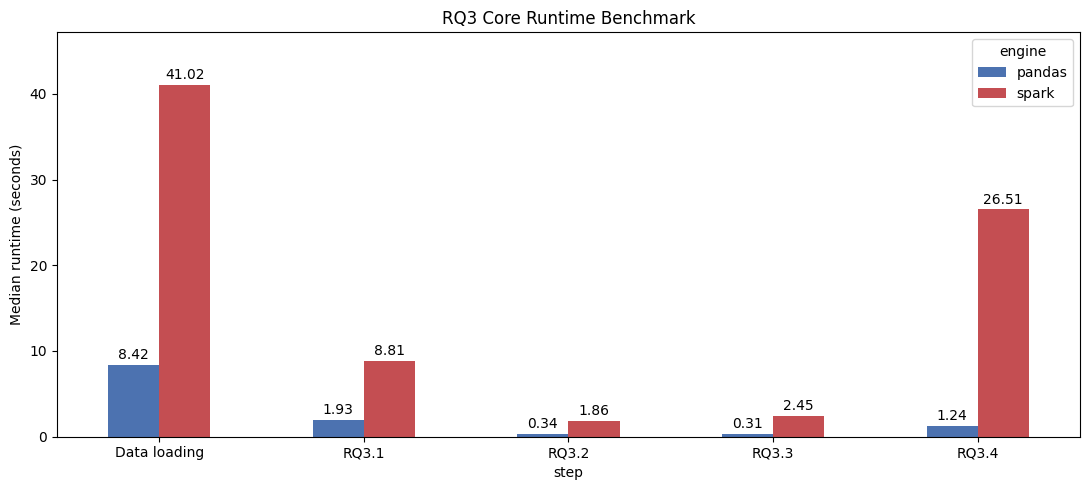

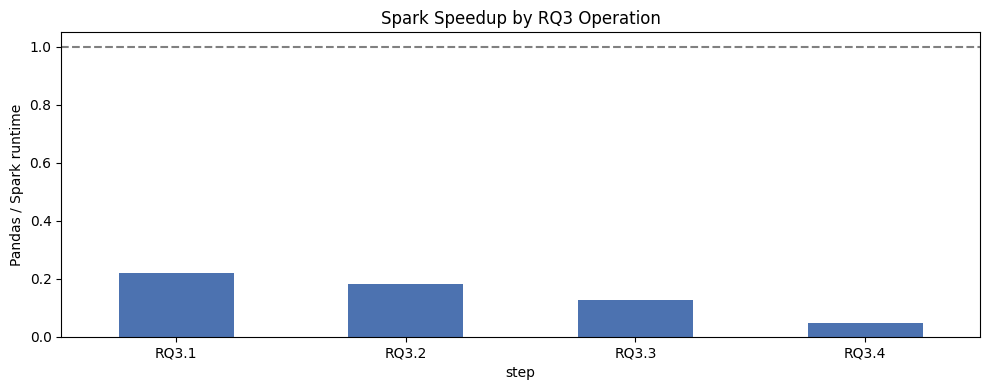

In [6]:
summary=raw.groupby(['step','engine']).seconds.agg(['median','min','max']).reset_index()
summary.to_csv(OUT+'runtime_statistics.csv',index=False)
runtime=summary.pivot(index='step',columns='engine',values='median').reindex(['Data loading']+steps)
runtime.loc['Total analysis']=runtime.loc[steps].sum()
runtime['spark_speedup']=runtime.pandas/runtime.spark
runtime.to_csv(OUT+'runtime_comparison.csv')
display(runtime.round(3))
ax=runtime.loc[['Data loading']+steps,['pandas','spark']].plot.bar(figsize=(11,5),rot=0,color=['#4C72B0','#C44E52'])
ax.set_ylabel('Median runtime (seconds)'); ax.set_title('RQ3 Core Runtime Benchmark')
for c in ax.containers: ax.bar_label(c,fmt='%.2f',padding=2)
ax.margins(y=.15); plt.tight_layout(); plt.savefig(OUT+'runtime_comparison.png',dpi=300); plt.show()
ax=runtime.loc[steps,'spark_speedup'].plot.bar(figsize=(10,4),rot=0,color='#4C72B0')
ax.axhline(1,color='gray',linestyle='--'); ax.set_ylabel('Pandas / Spark runtime'); ax.set_title('Spark Speedup by RQ3 Operation')
plt.tight_layout(); plt.savefig(OUT+'spark_speedup.png',dpi=300); plt.show()

## E. Consolidated Benchmark Summary

In [7]:
def section(filename):
    if filename.startswith('lender_portfolio'): return 'RQ3.4'
    if filename in ['denial_by_state.csv','missing_state_summary.csv']: return 'RQ3.2'
    if filename in ['denial_by_lender.csv','lender_threshold_assessment.csv','denial_by_lender_size.csv','top_10_lenders.csv']: return 'RQ3.3'
    return 'RQ3.1'
comparison['step']=comparison.table.map(section)
final=runtime.loc[steps].copy()
final['export_correctness']=[('PASS' if comparison.loc[comparison.step.eq(s),'status'].eq('PASS').all() else 'REVIEW') for s in steps]
final['fresh_correctness']=[('PASS' if fresh.loc[fresh.step.eq(s),'status'].eq('PASS').all() else 'FAIL') for s in steps]
final['faster_engine']=np.where(final.spark_speedup>1,'Spark',np.where(final.spark_speedup<1,'Pandas','Tie'))
display(final.round(3)); final.to_csv(OUT+'benchmark_summary.csv')
S.unpersist(blocking=True)
print('Saved to',OUT)

engine,pandas,spark,spark_speedup,export_correctness,fresh_correctness,faster_engine
step,,,,,,
RQ3.1,1.927,8.808,0.219,PASS,PASS,Pandas
RQ3.2,0.338,1.861,0.182,PASS,PASS,Pandas
RQ3.3,0.312,2.451,0.127,PASS,PASS,Pandas
RQ3.4,1.241,26.509,0.047,PASS,PASS,Pandas


Saved to /content/drive/MyDrive/hmda/rq3_benchmark/


### Insight — Benchmark Interpretation
Interpret the measured results only after execution. Export checks validate existing outputs; fresh checks validate the timed count/sum workload. Differences in tied lender selection may affect previous exports. Local single-machine Spark performance is not evidence of distributed cluster scalability. OS caching, parquet layout, JVM warm-up and shared memory pressure can influence timings.